... to the only wise God!

# Nested 'for...' Loops and Application to Discretized Reservoirs

**Learning Outcomes**

At the end of this week, learners should be able to:

+ **recognize** use-cases that require nesting 'for...' loops;
+ **construct** nested 'for...' loops by placing one loop in another loop;
+ **analyze** the relationships between loops nested together - order and frequency of execution.
+ **understand** the concept of discretizing a reservoir into gridblocks;
+ **work** with the two gridblock indexing techniques - natural ordering and engineering ordering;
+ **write** codes to make computations in discretized reservoirs.

## Nested 'for...' Loops

Sometimes, each element in the iterable object (collection) you are looping through is also an iterable object with sub-elements to be looped through.

Think of the sitting arrangement in your class. There are rows of seat in the class; and for every row, there are seats (columns).

If you need to execute some statement(s) for every column of every row, you will have to:

+ Construct an outer '_for..._' loop to iterate through the rows
+ Then, construct an inner '_for..._' loop to iterate through the columns of each row.

This arrangement of one loop inside another loop is called **_Nested for... loops_**.

This is not limited to just two (2) loops; you could have multiple loops nested together.

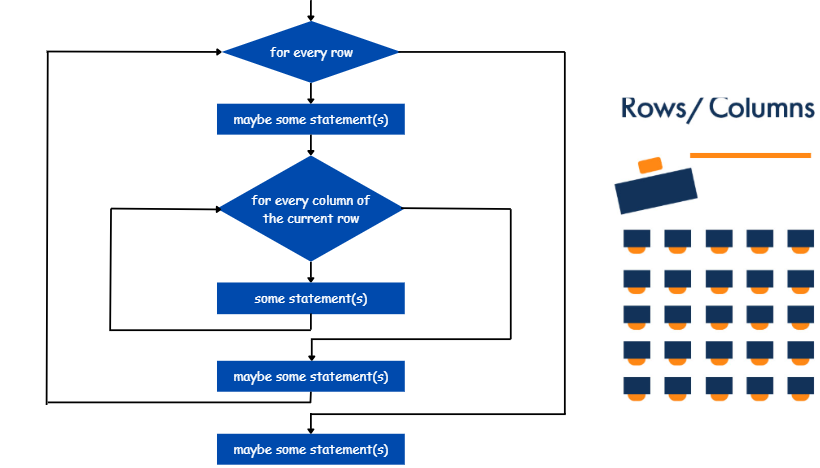

In [2]:
rows = ['Row 1', 'Row 2', 'Row 3']
columns = ['Column 1', 'Column 2', 'Column 3', 'Column 4']


for row in rows:                                            # header of outer loop
    print(f'We are in {row}\n')                             # body of outer loop begins
    

    for column in columns:                                   # header of inner loop (but body of outer loop)
        print(f'We are in {column} of {row}')                # body of inner loop (still body of outer loop)
                                              
    print(f'\nWe are leaving {row}\n')                       # not in inner loop, (but still body of outer loop)
        
print('Outta here')                                          # not in any loop

We are in Row 1

We are in Column 1 of Row 1
We are in Column 2 of Row 1
We are in Column 3 of Row 1
We are in Column 4 of Row 1

We are leaving Row 1

We are in Row 2

We are in Column 1 of Row 2
We are in Column 2 of Row 2
We are in Column 3 of Row 2
We are in Column 4 of Row 2

We are leaving Row 2

We are in Row 3

We are in Column 1 of Row 3
We are in Column 2 of Row 3
We are in Column 3 of Row 3
We are in Column 4 of Row 3

We are leaving Row 3

Outta here


### Counting with Nested '_for..._' Loops

In [3]:
rows = ['Row 1', 'Row 2', 'Row 3']
columns = ['Column 1', 'Column 2', 'Column 3', 'Column 4']

row_counter = 0                                      # initializing row counter

for row in rows:                                            
    row_counter = row_counter + 1                   # incrementing row counter
    
    column_counter = 0                              # initializing column counter
    for column in columns:                                   
        column_counter = column_counter + 1         # incrementing coulmn counter
        
    print(f'There are {column_counter} columns in {row}')
                                              
    
print(f'There are {row_counter} rows in the class')
        
print('Outta here')                                          

There are 4 columns in Row 1
There are 8 columns in Row 2
There are 12 columns in Row 3
There are 3 rows in the class
Outta here


### PE application of 'for' loop: computing STOIIP for a discetized reservoir.

Hydrocarbon reservoirs are heterogenous - properties of the reservoir (porosity, permeability, water saturation etc) varies from one point in the reservoir to the other.

So, the challenge is what value (say of porosity) should be used in computing (say STOIIP)?

The solution is to divide (discretize) the reservoir into small regions (gridblocks) such that gridblock is homogenous (uniform value of property in each block).

Upon discretization, the reservoir becomes rows and columns of gridblocks!

Nested loops can then be constructed to '_walk_' through the gridblocks (row after row, column after column)

For each such iteration, STOIIP is computed for each gridblock.

As the computation proceeds, the STOIIP values are being aggregated (summed up).

At the end of the loops, all STOIIP values would have been aggregated to give the total STOIIP for the entire reservoir.

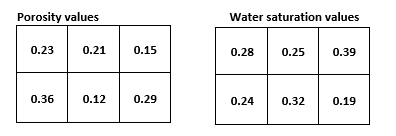

#### Gridblock Ordering

With the reservoir so discretized, it becomes neccessary to have a way of referring to each block.

Each gridblock is referred to with a number (index), or a pair of numbers (indices) - more students are referred to with matric numbers.

The scheme by which gridblocks are allocated these numbers is known as **Gridblock Ordering**

There are two types of Gridblock Ordering Techniques - **Natural Ordering** and **Engineering Ordering**

#### Natural Ordering

The gridblocks are referred to by their positions in the grid - moving left to right first; then, south to north.

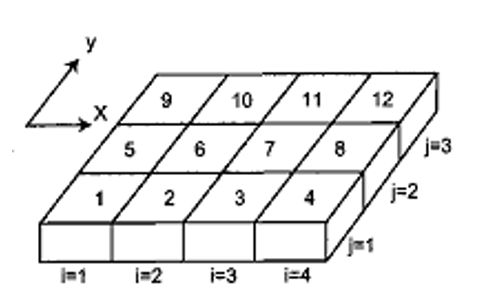

**Engineering Ordering**

Each gridblock is referred to by a pair of number, **_i_** and **_j_**; written as **_i , j_**

Index **_i_** refers to the column where the gridblock is located (numbered from left to right)

Index **_j_** refers to the row where the gridblock is located (numbered from south to north)

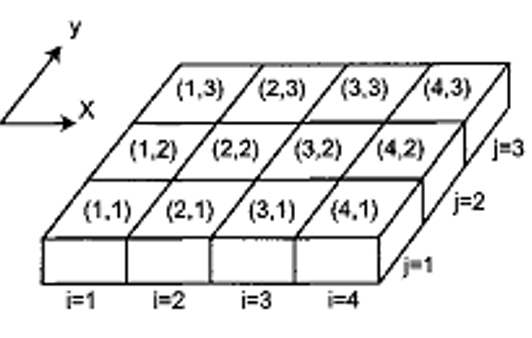

#### Converting from Engineering Ordering to Natural Ordering

A key question arises: which gridblock notation should be used?

Actually, both of them are useful at different times!

Considering that the engineering ordering is based on Indices _i_ and _j_ which respectively correspond to the _Column number_ and _row number_, it fits well into the workings of nested '_for..._' loops (since the loops are defined for rows and columns).

However, in passing in input data values (such as porosity etc) and in reporting model outputs (say STOIIP), it is more convinient to work with the natural ordering.

You want to say, the STOIIP in **_Block 10_** is ...; you probably don't want to say the STOIIP in **_Block 2,3_** is ...

The formular below is used to convert the _i, j_ indices to natural ordering.

$$n = n_x(j-1)+i$$

... where $n_x$ is the number of columns in the discretized model

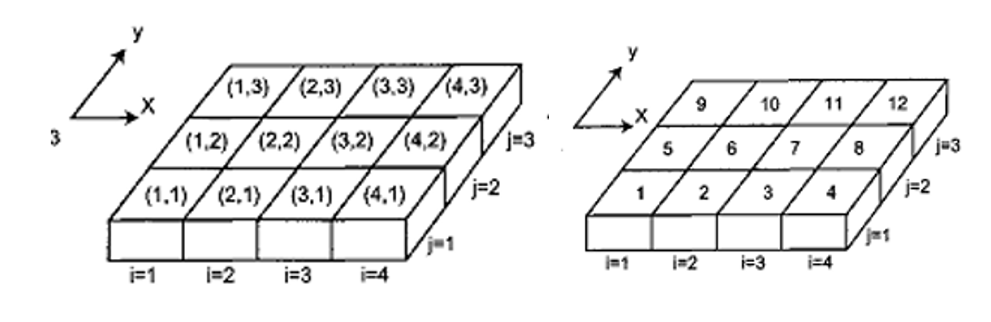

### It's time to put it all together: Computing STOIIP for a Discretized Reservoir

Let's write a code to compute STOIIP for the discretized model below:

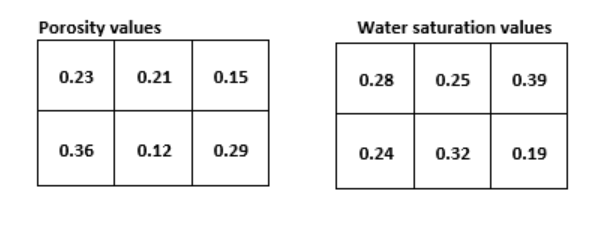

Values for other model parameters are given below:

+ Length of reservoir in x-direction, $L_x = 1200$ ft.
+ Length of reservoir in y-direction, $L_y = 1000$ ft.
+ Thickness of the reservoir, $h = 40$ ft.
+ Initial oil formation volume factor, $B_{oi} = 1.2$

The equation to calculate STOIIP is given thus:

$$N = \frac{7758Ah\phi(1-s_{wi})}{B_{oi}}$$

... where $A$ is area of the gridblock, in acres (not $ft^2$), and is given as:

$$A = \frac{\Delta x \times \Delta y}{43560}$$

... where $\Delta x$ and $\Delta y$ are the length of a gridblock in x- and y-directions 

$$\Delta x = \frac{L_x}{n_x}$$

$$\Delta y = \frac{L_y}{n_y}$$

... where $n_x$ and $n_y$ are the number of gridblocks in x- and y- directtions.

In [1]:
# input statements
Lx = float(input('What is the length of the reservoir in x-direction?\n'))
Ly = float(input('What is the length of the reservoir in y-direction?\n'))
h = float(input('What is the thickness of the reservoir?\n'))
nx = int(input('How many blocks there are in x-axis?\n'))
ny = int(input('How many blocks there are in y-axis?\n'))
boi = float(input('What is the value of initial oil FVF?\n'))

What is the length of the reservoir in x-direction?
1000
What is the length of the reservoir in y-direction?
500
What is the thickness of the reservoir?
15
How many blocks there are in x-axis?
2
How many blocks there are in y-axis?
2
What is the value of initial oil FVF?
1.2


In [2]:
# discretizing the reservoir

delta_x = Lx/nx
delta_y = Ly/ny

print(delta_x, delta_y)

500.0 250.0


In [3]:
# calculating the area per block
area = (delta_x*delta_y)/43560
print(area)

2.869605142332415


In [4]:
# initializing aggregator variable

total_stoiip = 0
stoiip_list = []

In [ ]:
[0.2, 0.4, 0.34, 0.18]

In [ ]:
def stoiipdisc(Lx, Ly, nx, ny, h, boi, poro_list, swi_list):

    delta_x = Lx/nx
    delta_y = Ly/ny
    area = (delta_x*delta_y)/43560
    
    total_stoiip = 0
    stoiip_list = []
    
    
    for j in range(1,ny+1):
        for i in range(1,nx+1):
            block_n_order = (nx*(j-1))+i
            print(f'Computing STOIIP for Block{block_n_order}, i.e Block [{i},{j}] now...\n')
            block_stoiip = (7758*area*h*poro_list[block_n_order-1]*(1-swi_list[block_n_order-1]))/boi
            total_stoiip = total_stoiip + block_stoiip    # aggregation
            stoiip_list.append(block_stoiip)
        
            

    

In [5]:
# the 'for' loop
for j in range(1,ny+1):
    for i in range(1,nx+1):
        block_n_order = (nx*(j-1))+i
        print(f'Computing STOIIP for Block{block_n_order}, i.e Block [{i},{j}] now...\n')
        poro = float(input(f'What is the value of porosity for Block {block_n_order}?'))
        sw = float(input(f'What is the value of water saturation for Block {block_n_order}?'))
        block_stoiip = (7758*area*h*poro*(1-sw))/boi
        total_stoiip = total_stoiip + block_stoiip    # aggregation
        stoiip_list.append(block_stoiip)
        
        print(f'\nThe amount of oil in Block {block_n_order}, i.e Block [{i},{j}] is {round(block_stoiip, 2)} STB\n\n')
        
        
    print(f'\nThis is the end of computations for Row {j}\n\n')


Computing STOIIP for Block1, i.e Block [1,1] now...

What is the value of porosity for Block 1?0.2
What is the value of water saturation for Block 1?0.28

The amount of oil in Block 1, i.e Block [1,1] is 40072.31 STB


[40072.31404958678]
Computing STOIIP for Block2, i.e Block [2,1] now...

What is the value of porosity for Block 2?0.23
What is the value of water saturation for Block 2?0.17

The amount of oil in Block 2, i.e Block [2,1] is 53123.64 STB


[40072.31404958678, 53123.64411157025]

This is the end of computations for Row 1


Computing STOIIP for Block3, i.e Block [1,2] now...

What is the value of porosity for Block 3?0.18
What is the value of water saturation for Block 3?0.34

The amount of oil in Block 3, i.e Block [1,2] is 33059.66 STB


[40072.31404958678, 53123.64411157025, 33059.65909090909]
Computing STOIIP for Block4, i.e Block [2,2] now...

What is the value of porosity for Block 4?0.26
What is the value of water saturation for Block 4?0.35

The amount of oil in Bl

In [7]:
# displaying the final results.
print(f'The amount of oil in the entire reservoir is {round(total_stoiip, 2)} STB')
print(stoiip_list)

The amount of oil in the entire reservoir is 173284.93 STB
[40072.31404958678, 53123.64411157025, 33059.65909090909, 47029.31301652893]
